# Continuous-time blocks

Plants, analog filters and sensors live in continuous time; controllers and
DSP in discrete time. Continuous blocks hold each input sample over the
sample interval (zero-order hold, as a DAC does), integrate the state to
the next sample instant and output the sampled result. So their output at
sample $k$ depends on inputs up to $k-1$: a loop through one needs no extra
delay.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

import sigline as sl

## 1. An ODE as a block

A mass on a spring with damping, driven by a force $u$:
$\ddot x = -4\dot x - 100x + 100u$, as a first-order system in
$(x, \dot x)$. `f(t, x, u)` returns the derivative, `g(t, x)` picks the
output. A unit step at 0.1 s falls on a sample, so from there the result
must equal one `solve_ivp` call.

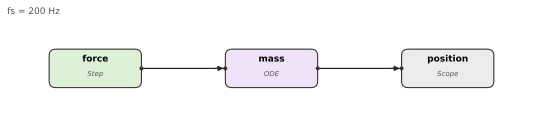

In [2]:
fs = 200.0


def spring(t, x, u):
    return [x[1], -4 * x[1] - 100 * x[0] + 100 * u]


mass = sl.ODE(spring, [0.0, 0.0], g=lambda t, x: x[0], name="mass")
pos = sl.Scope("position")
sl.Step(0.1, name="force") >> mass >> pos
d = sl.Diagram(pos, fs=fs)
d

max |error| vs one solve_ivp: 2.9e-11


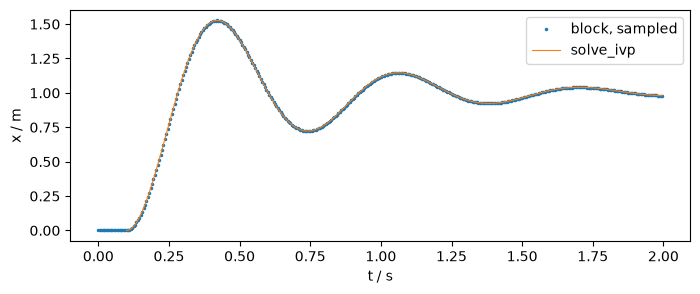

In [3]:
d.run(2.0)
sol = solve_ivp(
    lambda t, x: spring(t, x, 1.0),
    (0.1, 2.0),
    [0, 0],
    t_eval=d.t[20:],
    rtol=1e-10,
    atol=1e-12,
)
print(f"max |error| vs one solve_ivp: {np.max(np.abs(pos.data[20:] - sol.y[0])):.1e}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(d.t, pos.data, ".", ms=3, label="block, sampled")
ax.plot(sol.t, sol.y[0], lw=0.8, label="solve_ivp")
ax.set(xlabel="t / s", ylabel="x / m")
ax.legend()
plt.show()

## 2. Linear systems: exact, and fast

`ContinuousLTI(num, den)` takes a transfer function (or `A=, B=, C=, D=`).
For inputs held over each sample, the matrix exponential gives the exact
discrete system, so no integration error remains. Below: the same
second-order low-pass, $H(s) = \omega_0^2 / (s^2 + 2\zeta\omega_0 s +
\omega_0^2)$, exactly and integrated by `solve_ivp`, against the closed-form
step response.

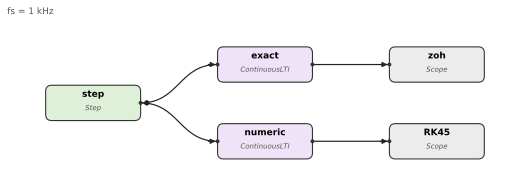

In [4]:
f0, zeta = 10.0, 0.2
w0 = 2 * np.pi * f0
num, den = [w0**2], [1.0, 2 * zeta * w0, w0**2]

step = sl.Step(0.0, name="step")
exact = sl.ContinuousLTI(num, den, name="exact")
numeric = sl.ContinuousLTI(num, den, method="RK45", name="numeric")
y_exact, y_numeric = sl.Scope("zoh"), sl.Scope("RK45")
step >> exact >> y_exact
step >> numeric >> y_numeric
d2 = sl.Diagram(y_exact, fs=1000.0)
d2

0.5 s of both: 0.47 s
zoh : max |error| vs closed form 1.8e-15
RK45: max |error| vs closed form 5.1e-10


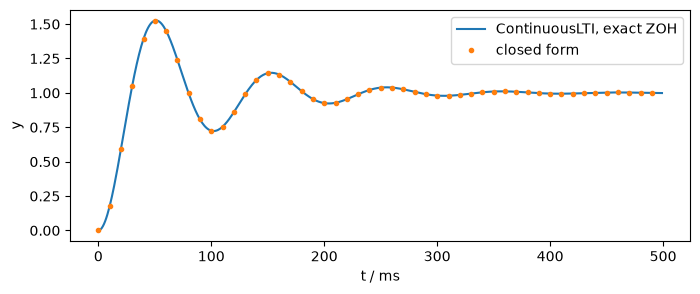

In [5]:
t0 = time.perf_counter()
d2.run(0.5)
print(f"0.5 s of both: {time.perf_counter() - t0:.2f} s")

t = d2.t
wd = w0 * np.sqrt(1 - zeta**2)
closed = 1 - np.exp(-zeta * w0 * t) * (np.cos(wd * t) + zeta * w0 / wd * np.sin(wd * t))
for sc in (y_exact, y_numeric):
    worst = np.max(np.abs(sc.data - closed))
    print(f"{sc.name:4s}: max |error| vs closed form {worst:.1e}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(1e3 * t, y_exact.data, label="ContinuousLTI, exact ZOH")
ax.plot(1e3 * t[::10], closed[::10], "o", ms=3, label="closed form")
ax.set(xlabel="t / ms", ylabel="y")
ax.legend()
plt.show()

## 3. A discrete controller and a nonlinear plant

A water tank, $A\,\dot h = q - c\sqrt h - q_\mathrm{leak}$, filled by a
pump limited to $0 \le q \le 3$. A PI controller at 100 Hz sets the pump
from the level error. The plant is a callable object, so its parameters are
attributes; at 6 s a leak opens between two runs.

The loop runs through the tank, sample by sample. `solve_ivp` methods have
no compiled kernel, so the diagram warns that this loop runs in Python.

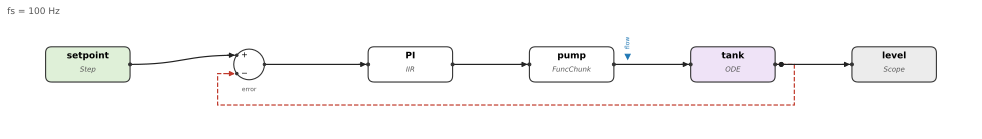

In [6]:
class Tank:
    area, c, leak = 1.0, 0.5, 0.0

    def __call__(self, t, h, q):
        return [(q - self.c * np.sqrt(max(h[0], 0.0)) - self.leak) / self.area]


fs, kp, ki = 100.0, 2.0, 1.0
tank = Tank()
setpoint = sl.Step(0.5, before=0.2, after=1.0, name="setpoint")
error = sl.Sum("+-", name="error")
pi = sl.IIR(b=[kp + ki / fs, -kp], a=[1.0, -1.0], name="PI")
pump = sl.FuncChunk(lambda u: np.clip(u, 0.0, 3.0), name="pump")
plant = sl.ODE(tank, [0.2], inputs=("q",), outputs=("h",), method="LSODA", name="tank")
level = sl.Scope("level")

setpoint >> error["x0"]
error >> pi >> pump >> plant >> level
plant >> error["x1"]
d3 = sl.Diagram(level, fs=fs)
flow = d3.probe(pump, name="flow")
d3

/home/julian/Documents/sigline/src/sigline/diagram.py:403: RuntimeWarning: loop[error, PI, pump, tank] runs in Python (slow): tank: method 'LSODA'; RK4 compiles
  self._chunks(n, chunk)


[<LoopCluster loop[error, PI, pump, tank] python>]
t =  6.0 s: h = 1.0008, q = 0.4998 (theory 0.5000)
t = 12.0 s: h = 0.9950, q = 0.7018 (theory 0.7000)


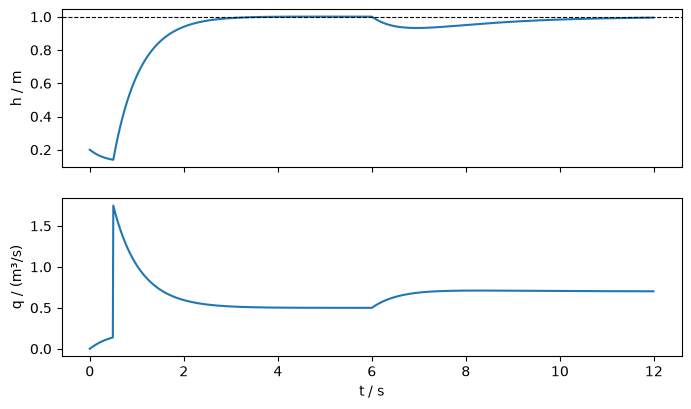

In [7]:
d3.run(6.0)
tank.leak = 0.2
d3.run(6.0)
print(d3.loops())

# steady state: inflow equals outflow, q = c sqrt(h) + leak at h = 1
for t_end, leak in ((6.0, 0.0), (12.0, 0.2)):
    k = int(t_end * fs) - 1
    print(
        f"t = {t_end:4.1f} s: h = {level.data[k]:.4f}, q = {flow.data[k]:.4f} "
        f"(theory {tank.c * 1.0 + leak:.4f})"
    )

fig, ax = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
ax[0].plot(d3.t, level.data)
ax[0].axhline(1.0, ls="--", c="k", lw=0.8)
ax[0].set(ylabel="h / m")
ax[1].plot(d3.t, flow.data)
ax[1].set(xlabel="t / s", ylabel="q / (m³/s)")
plt.show()

## 4. Compiled loops

With exact-ZOH `ContinuousLTI` or `ODE(method="RK4")` plants, every block
in the loop has a numba kernel, and the whole loop compiles. The timing
starts after the first chunk (Python) and the second (compiling, about a
second). The tank
linearised around $h = 1$ ($\dot{\delta h} = -\frac{c}{2A}\delta h +
\delta q / A$), in the same loop, compiled and in Python:

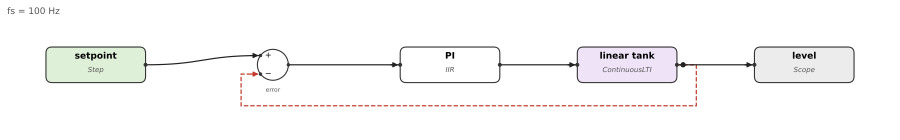

In [8]:
def linear_loop(mode):
    err = sl.Sum("+-", name="error")
    ctrl = sl.IIR(b=[kp + ki / fs, -kp], a=[1.0, -1.0], name="PI")
    lin = sl.ContinuousLTI([1.0], [tank.area, tank.c / 2], name="linear tank")
    out = sl.Scope("level")
    sl.Step(0.5, after=0.1, name="setpoint") >> err["x0"]
    err >> ctrl >> lin >> out
    lin >> err["x1"]
    return sl.Diagram(out, fs=fs, compile_loops=mode), out


d4, out4 = linear_loop(True)
d4

In [9]:
results = {}
for mode in (True, "python"):
    dd, out = linear_loop(mode)
    dd.run(n=2048)  # first chunk in python, the second compiles
    t0 = time.perf_counter()
    dd.run(n=200 * 1024)
    dt = time.perf_counter() - t0
    results[mode] = out.data
    print(f"{dd.loops()[0].mode:6s}: {1e9 * dt / (200 * 1024):8.0f} ns/sample")
print(f"max |difference|: {np.max(np.abs(results[True] - results['python'])):.1e}")

numba :      317 ns/sample


python:    71279 ns/sample
max |difference|: 0.0e+00


## Summary

- `ODE(f, x0, g=...)`: any continuous system; `solve_ivp` methods, or
  `method="RK4"` to compile inside loops.
- `ContinuousLTI(num, den)`: exact for held inputs, compiled over chunks.
- Loops through continuous blocks need no extra delay; they run sample by
  sample, compiled when every block has a kernel.